# 03 · Classification with XGBoost

**Objective.** Forecast, for a state/UT and crime head, whether registered cases next year go **down**,
stay **stable** or go **up** (±10%), and judge whether XGBoost beats a rule anyone could write in one line.

**Method.** Time-ordered split: train on feature years up to 2016, early-stop and tune on 2017-18, score
**once** on 2019 onwards. The full tuned comparison is produced by `python -m crimebase train`; this notebook
reads its saved results and re-fits the final XGBoost to look inside it.

**Contents.** 1 Data · 2 Baselines · 3 Model and training · 4 Tuning · 5 Evaluation (metrics, classification
report, confusion matrix, ROC, train/validation/test, paired tests, by year) · 6 Feature importance · 7 Reading the result

In [1]:
import numpy as np
import pandas as pd

from crimebase import viz
from crimebase.config import load_config

cfg = load_config()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_colwidth = 80
pd.options.display.width = 140

import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice from optuna, harmless

from crimebase.evaluate import CLASS_NAMES
from crimebase.experiment import final_fit
from crimebase.explain import contributions, importance, signed_effect
from crimebase.features import FEATURES
from crimebase.models import DEFAULTS, fit
from crimebase.pipeline import load_matrix
from crimebase.report import paired_table, scores_table, tuning_table
from crimebase.results import load_comparison, scores_by_year
from crimebase.splits import dev_mask, holdout_mask, train_mask, val_mask

target = "y_trend"
m = load_matrix(cfg)
saved = load_comparison(cfg, target)  # written by `python -m crimebase train`
X, y = m[FEATURES], m[target]
tr, va, dev, te = (f(m, cfg.split, target) for f in (train_mask, val_mask, dev_mask, holdout_mask))

from crimebase.evaluate import classification_table
from crimebase.experiment import split_performance
from crimebase.report import prediction_mix_sentence, overfit_sentence
from crimebase.results import recompute_scores

extra = recompute_scores(saved, m, cfg)  # accuracy, macro precision and recall for every entry
names = {0: "down", 1: "stable", 2: "up"}

## 1. Data

In [2]:
rows = []
for split_name, mask in (("Train", tr), ("Validation", va), ("Test (held out)", te)):
    labels = y[mask].astype(int)
    rows.append({
        "Split": split_name,
        "Feature years": f"{m.year[mask].min()}-{m.year[mask].max()}",
        "Rows": int(mask.sum()),
        **{name: (labels == k).mean() for k, name in names.items()},
    })
viz.show_table(
    pd.DataFrame(rows).set_index("Split"),
    "Table 1. Data splits and class balance",
    {"Rows": "{:,}", "down": "{:.1%}", "stable": "{:.1%}", "up": "{:.1%}"},
)

,Feature years,Rows,down,stable,up
Split,,,,,
Train,2001-2016,"24,114",28.0%,38.1%,33.8%
Validation,2017-2018,"4,012",28.2%,31.2%,40.6%
Test (held out),2019-2021,"12,268",32.8%,29.8%,37.3%


Each row is one state/UT and crime head in one year, with 29 features built only from that year and earlier
(level, growth, four-year mean and spread, comparison with other states, justice-pipeline ratios, scope,
category, state). The classes are reasonably balanced, so chance accuracy is about one in three.

## 2. Baselines to beat

In [3]:
baseline_rows = ["majority", "persistence", "mean_reversion", "binned_g1"]
viz.show_table(
    scores_table(saved, extra).set_index("Model").loc[[viz.label(e) for e in baseline_rows]],
    "Table 2. Baselines on the held-out years (no machine learning)",
    None,
)

,Accuracy,Precision (macro),Recall (macro),F1 (macro) [95% CI],ROC-AUC [95% CI],Log loss,Trees
Model,,,,,,,
Majority class,0.298,0.099,0.333,"0.153 [0.145, 0.162]","0.500 [0.500, 0.500]",1.107,
Persistence rule,0.316,0.304,0.318,"0.302 [0.285, 0.319]",n/a,n/a,
Mean-reversion rule,0.394,0.412,0.403,"0.387 [0.371, 0.404]",n/a,n/a,
Last-year-direction table,0.378,0.252,0.353,"0.269 [0.255, 0.283]","0.560 [0.549, 0.572]",1.095,


*Persistence* predicts "next year moves like last year"; *mean reversion* predicts the opposite; the
*last-year-direction table* learns the class mix per last-year direction from the training years. Macro-F1
averages the F1 of down, stable and up, so a model cannot score well by ignoring a class.

## 3. Model and training: XGBoost with default parameters

trained on 24,114 rows; stopped after round 215, keeping round 115


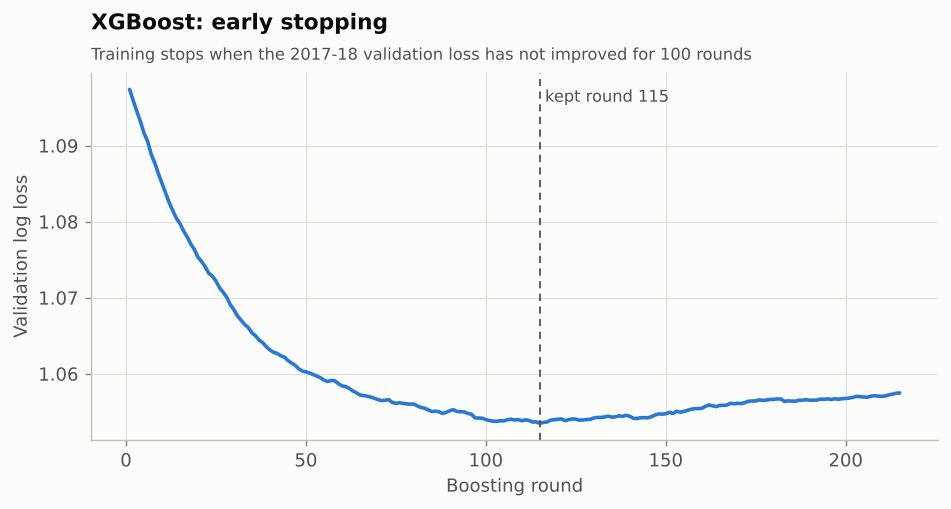

In [4]:
stopped = fit("xgboost", X[tr], y[tr], X[va], y[va], seed=cfg.seed)
history = stopped.model.evals_result()["validation_0"]["mlogloss"]
print(f"trained on {int(tr.sum()):,} rows; stopped after round {len(history)}, keeping round {stopped.best_iteration}")
viz.show(viz.plot_learning_curve(history, stopped.best_iteration, "XGBoost: early stopping"))

## 4. Hyperparameter tuning with Optuna

40 trials; cross-validated log loss 1.0408 (default) -> 1.0379 (best)


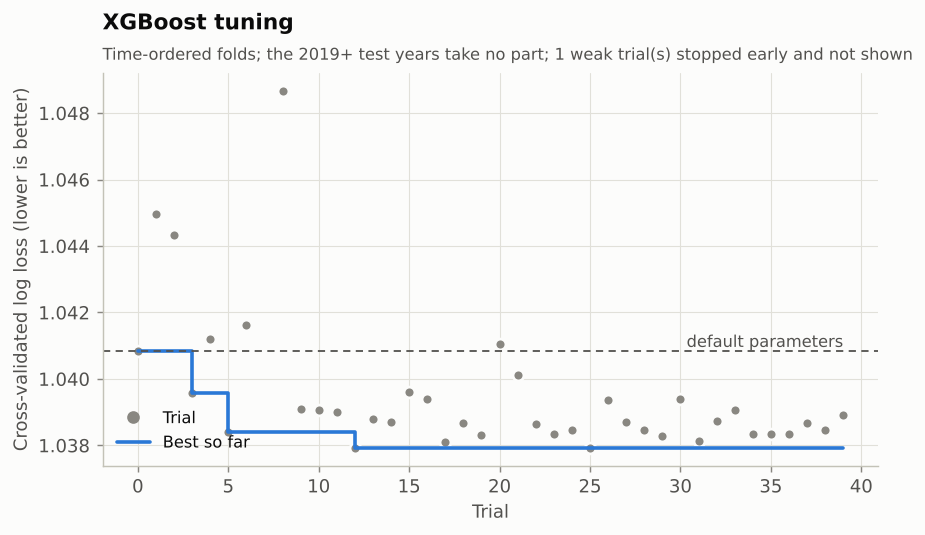

,default,tuned
learning_rate,0.030,0.034
max_depth,5.000,2.000
subsample,0.800,0.600
colsample_bytree,0.700,0.485
min_child_weight,10.000,16.112
reg_lambda,5.000,16.282
reg_alpha,0.000,5.952


In [5]:
tuned = saved.tuning["xgboost"]
trials = pd.read_csv(cfg.paths.metrics / f"{target}_trials_xgboost.csv")
print(f"{tuned['n_trials']} trials; cross-validated log loss {tuned['default_cv_log_loss']:.4f} (default) -> "
      f"{tuned['best_cv_log_loss']:.4f} (best)")
viz.show(viz.plot_tuning(trials, tuned["default_cv_log_loss"], "XGBoost tuning"))
viz.show_table(
    pd.DataFrame({"default": {**DEFAULTS["xgboost"], "reg_alpha": 0.0}, "tuned": tuned["best_params"]}),
    "Table 3. XGBoost hyperparameters, default and tuned",
    "{:.3f}",
)

Each trial is scored on four expanding time folds (validate on 2009-10, 2011-12, 2013-14 and 2017-18, always
training on earlier years). The default parameters are trial 0, so tuning can only match or improve on them
*on those folds*. Whether that carries over to the held-out years is the next section.

## 5. Evaluation on the held-out years

### 5.1 Metrics summary

,Accuracy,Precision (macro),Recall (macro),F1 (macro) [95% CI],ROC-AUC [95% CI],Log loss,Trees
Model,,,,,,,
Majority class,0.298,0.099,0.333,"0.153 [0.145, 0.162]","0.500 [0.500, 0.500]",1.107,
Mean-reversion rule,0.394,0.412,0.403,"0.387 [0.371, 0.404]",n/a,n/a,
XGBoost (default),0.424,0.434,0.426,"0.417 [0.398, 0.434]","0.609 [0.585, 0.630]",1.069,115
XGBoost (tuned),0.417,0.425,0.418,"0.409 [0.391, 0.427]","0.611 [0.589, 0.631]",1.065,181


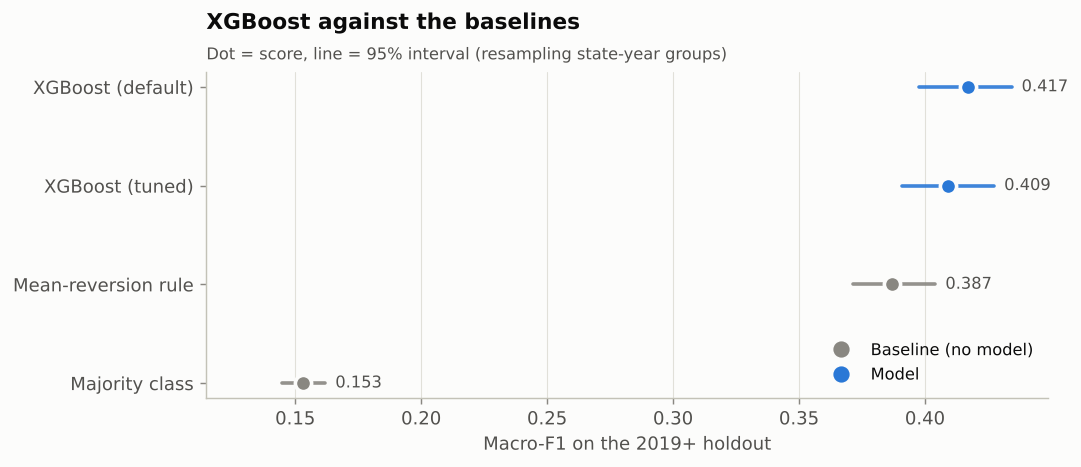

In [6]:
shown = ["majority", "mean_reversion", "xgboost_default", "xgboost_tuned"]
viz.show_table(
    scores_table(saved, extra).set_index("Model").loc[[viz.label(e) for e in shown]],
    "Table 4. Test-set metrics (precision and recall are macro averages; ROC-AUC is one-vs-rest)",
    None,
)
viz.show(viz.plot_scores(saved.scores.loc[shown], title="XGBoost against the baselines"))

### 5.2 Classification report (tuned XGBoost)

,precision,recall,f1-score,support
down,0.392,0.593,0.472,"4,029"
stable,0.446,0.327,0.377,"3,658"
up,0.437,0.333,0.378,"4,581"
accuracy,–,–,0.417,"12,268"
macro avg,0.425,0.418,0.409,"12,268"
weighted avg,0.425,0.417,0.409,"12,268"


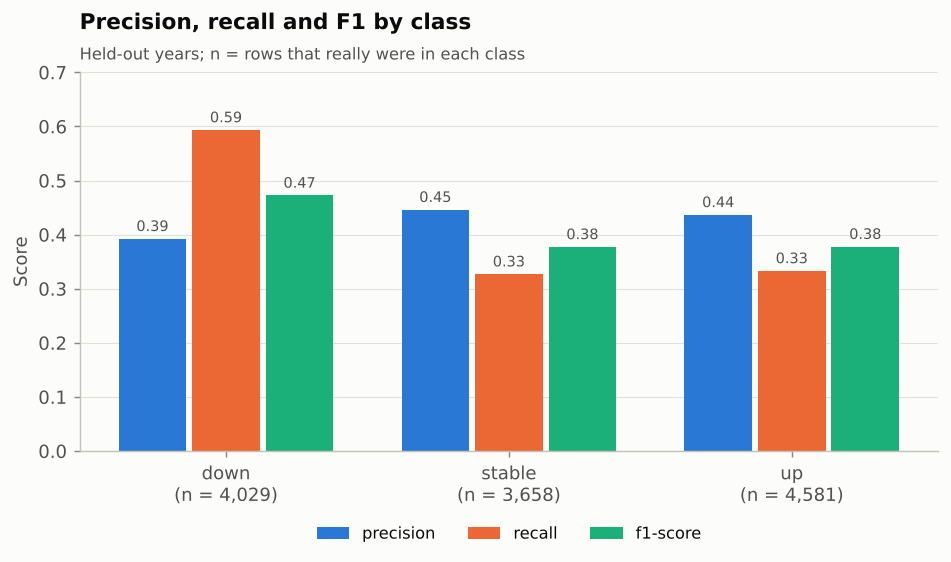

In [7]:
proba = saved.proba("xgboost_tuned").to_numpy()
y_true = saved.predictions.y_true.to_numpy()
report = classification_table(y_true, proba.argmax(axis=1))
viz.show_table(
    report,
    "Table 5. Classification report on the held-out years",
    {"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:,}"},
)
viz.show(viz.plot_class_metrics(report))

### 5.3 Confusion matrix

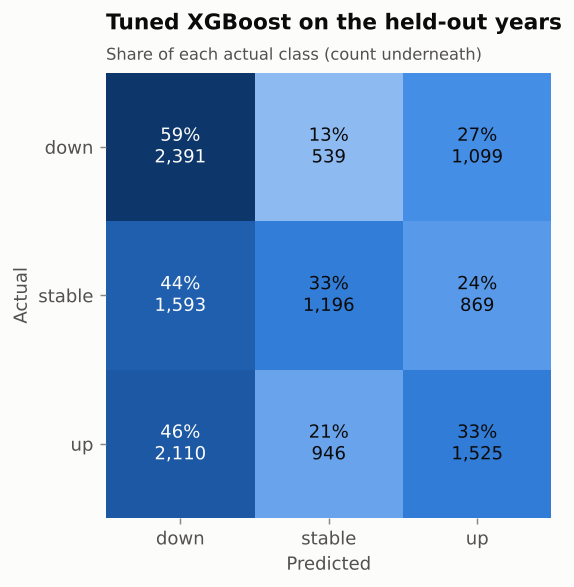

Actual mix of the held-out rows: down 33%, stable 30%, up 37%. Mix the model predicted: down 50%, stable 22%, up 28%.


In [8]:
viz.show(viz.plot_confusion(y_true, proba, "Tuned XGBoost on the held-out years"))
print(prediction_mix_sentence(y_true, proba))

### 5.4 ROC curves

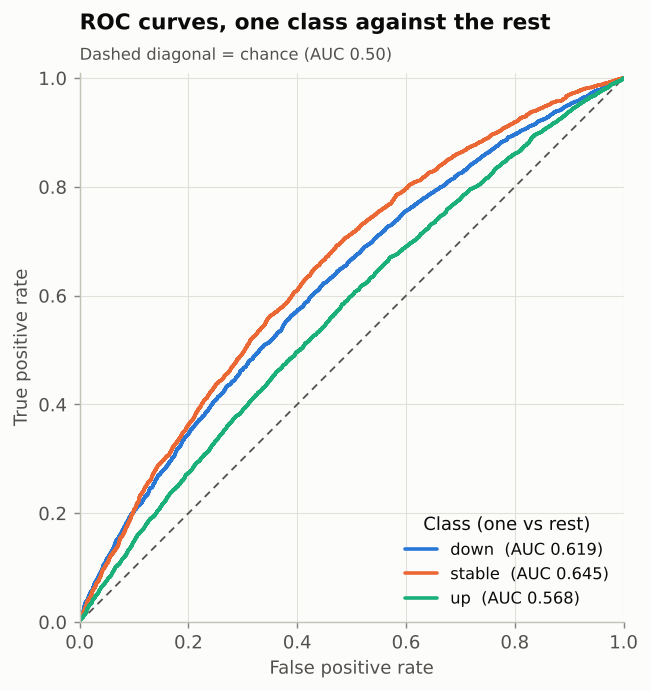

In [9]:
viz.show(viz.plot_roc(y_true, proba))

### 5.5 Train, validation and test: is it overfitting?

In [10]:
perf = split_performance(m, cfg, target, "xgboost", tuned["best_params"])
viz.show_table(
    perf.rename(columns={"years": "feature years", "precision_macro": "precision (macro)",
                         "recall_macro": "recall (macro)", "macro_f1": "F1 (macro)", "auc_ovr": "ROC-AUC"}),
    "Table 6. One model scored on its training, validation and test rows",
    {"rows": "{:,}", "accuracy": "{:.3f}", "precision (macro)": "{:.3f}", "recall (macro)": "{:.3f}",
     "F1 (macro)": "{:.3f}", "ROC-AUC": "{:.3f}", "log_loss": "{:.3f}"},
)
print(overfit_sentence(perf))

,feature years,rows,accuracy,precision (macro),recall (macro),F1 (macro),balanced_acc,f1_down,f1_stable,f1_up,log_loss,ROC-AUC
Train,2001-2016,"24,114",0.492,0.496,0.497,0.487,0.496826,0.494355,0.549106,0.418861,1.008,0.685
Validation,2017-2018,"4,012",0.418,0.436,0.434,0.413,0.433816,0.470026,0.382282,0.385628,1.054,0.628
Test,2019-2021,"12,268",0.408,0.419,0.412,0.390,0.411836,0.497114,0.354360,0.318611,1.074,0.604


Macro-F1 is 0.487 on the training years, 0.413 on validation and 0.390 on test: a train-to-test gap of 0.097. The model fits the rows it was trained on better than unseen years, so the held-out numbers, not the training ones, are the result.


This table uses a model fitted on the training years only, so the three rows are comparable. The headline
test numbers above refit on train + validation first; adding the more recent 2017-18 years is why they are
higher than this table's test row.

### 5.6 Paired tests against the rule and the default

In [11]:
paired = paired_table(saved)
viz.show_table(
    paired[(paired.A.str.contains("XGBoost")) & (paired.B.isin([viz.label("mean_reversion"), viz.label("xgboost_default")]))],
    "Table 7. Difference on the same bootstrap resamples (A minus B)",
    None,
)

,A,B,Metric,A - B [95% CI],Excludes 0
0,XGBoost (tuned),Mean-reversion rule,macro-F1,"0.022 [0.003, 0.042]",yes
1,XGBoost (tuned),XGBoost (default),macro-F1,"-0.008 [-0.015, -0.0004]",yes
2,XGBoost (tuned),XGBoost (default),ROC-AUC,"0.002 [-0.003, 0.007]",no


### 5.7 Year by year

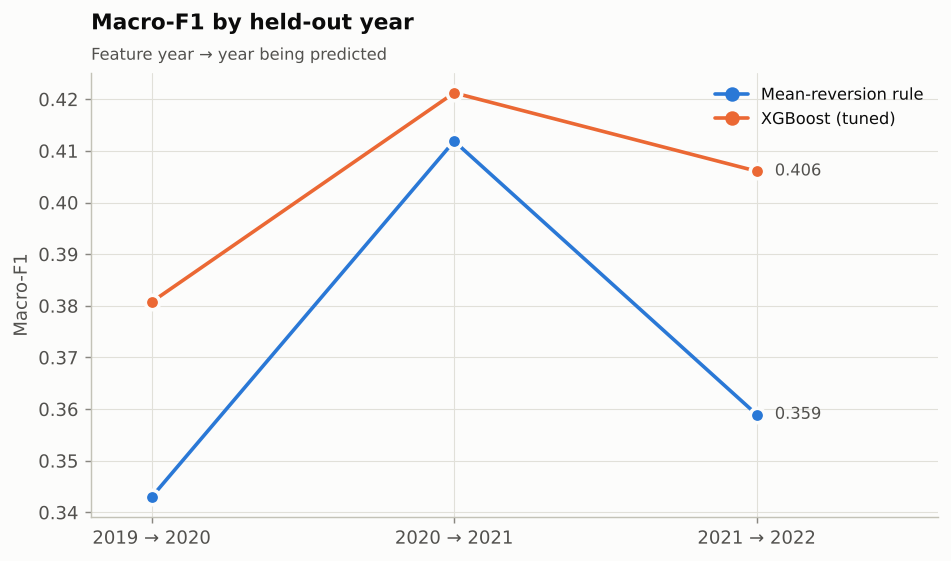

,Mean-reversion rule,XGBoost (tuned)
feature year,,
2019,0.343,0.381
2020,0.412,0.421
2021,0.359,0.406


In [12]:
by_year = scores_by_year(saved, m, cfg, ["mean_reversion", "xgboost_tuned"])
viz.show(viz.plot_by_year(by_year, "Macro-F1 by held-out year"))
viz.show_table(by_year.rename(columns=viz.label).rename_axis("feature year"), "Table 8. Macro-F1 by held-out year", "{:.3f}")

## 6. Feature importance

TreeSHAP gives each feature's push on each class's log-odds for every held-out row; the bars average its size.

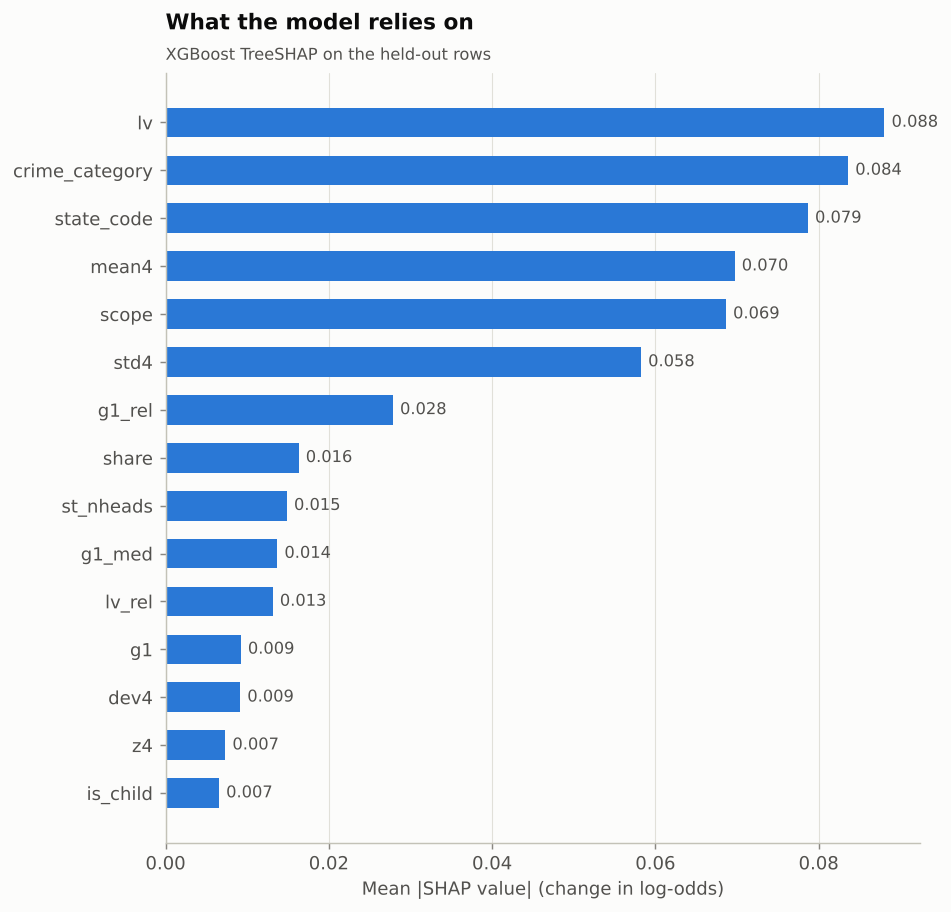

,down,stable,up,total
lv,0.127,0.132,0.006,0.088
crime_category,0.105,0.036,0.109,0.084
state_code,0.056,0.085,0.096,0.079
mean4,0.064,0.140,0.004,0.070
scope,0.029,0.125,0.052,0.069
std4,0.094,0.081,0.001,0.058
g1_rel,0.041,0.010,0.033,0.028
share,0.034,0.000,0.015,0.016
st_nheads,0.024,0.013,0.008,0.015
g1_med,0.007,0.001,0.033,0.014


In [13]:
final, trees = final_fit("xgboost", m, cfg, target, tuned["best_params"])
X_test = X[te]
contrib = contributions(final, X_test)
imp = importance(contrib, FEATURES)
viz.show(viz.plot_importance(imp))
viz.show_table(imp.head(10), "Table 9. Mean absolute SHAP value by class (top ten features)", "{:.3f}")

In [14]:
effects = pd.concat([signed_effect(contrib, X_test, k) for k in range(3)], axis=1)
viz.show_table(
    effects.loc[[f for f in imp.index[:10] if f in effects.index]],
    "Table 10. Rank correlation between a feature's value and its SHAP value, by class",
    "{:+.2f}",
)

,down,stable,up
lv,-0.82,+0.98,-0.87
mean4,-0.96,+0.95,-0.52
std4,+0.92,-0.87,+0.00
g1_rel,+0.81,-0.05,-0.75
share,+0.40,–,-0.66
st_nheads,+0.69,-0.43,-0.71
g1_med,-0.92,+0.34,+0.85


The second table is the rank correlation between a feature's value and its SHAP value for each class: positive
means higher values push that class up. It summarises direction only; trees can use the same feature in opposite
ways in different regions. Read from the table:

* **Bigger series are steadier.** Higher levels (`lv`, `mean4`) push strongly towards *stable* (+0.98, +0.96)
  and away from *down* and *up*; more volatile series (`std4`) are pushed away from *stable*.
* **Relative growth mean-reverts.** A state whose growth ran ahead of other states for the same head
  (`g1_rel`) is pushed towards *down* (+0.81) and away from *up* (−0.75).
* **Common growth persists.** When the median growth across states (`g1_med`) is high, the model leans
  *up* (+0.85) and away from *down* (−0.92).

## 7. Reading the result

* **A real but modest edge.** Tuned XGBoost scores 0.409 macro-F1 against 0.387 for the mean-reversion rule.
  The paired interval for the difference (+0.003 to +0.042) excludes zero, but only just. Its one-vs-rest AUC
  is about 0.61, where 0.50 is chance, so it ranks the right direction only somewhat better than a coin.
* **It beat the rule in every held-out year**, narrowly in 2020→2021 (+0.009) and by about 0.04 in the other two.
* **Tuning found nothing to improve.** The cross-validated log loss fell by only 0.003, the search settled on
  very shallow, heavily regularised trees (depth 2), and on the held-out years the tuned model scored 0.008
  *below* the default. When the best settings are the simplest ones, the signal is simple.
* **What it learned is mostly "what kind of series is this".** The model leans on the level (`lv`), the crime
  category, the state, the scope and the four-year mean and spread of the series, and last year's own growth
  (`g1`) ranks only 12th of 29. Persistent differences in drift and volatility between series matter more
  than short-run momentum.
* **It over-predicts "down" on the held-out years** (about half of rows against a third that really fell).
  The training years all precede 2019, and 2019-2021 includes the 2020 shock, so some of this is distribution
  shift. This project did not isolate the cause.

What would help next: per-capita rates (needs a population table), explicit handling of 2020, and an
early-warning framing (will this head drop or surge by more than 25%?), for which `y_drop` and `y_surge`
are already in the model matrix.